# Analiza slovenskih vzajemnih skladov

**Projektna naloga pri predmetu Uvod v programiranje**

## Uvod

Vzajemni sklad zbere denar številnih vlagateljev in ga naloži v delnice, obveznice ali druge naložbe. Vlagatelj s svojim vložkom kupi **enote sklada**. Cena ene enote se imenuje **vrednost enote premoženja (VEP)** in jo upravljavec izračuna vsak delovni dan. Če VEP naraste, je naložba vredna več.

**Donos** pove, za koliko odstotkov se je VEP spremenil v nekem obdobju. Če je bil VEP pred enim letom 10 €, danes pa je 11,50 €, je 12-mesečni donos 15 %.

V nalogi želim odgovoriti na vprašanje: **kam se je v zadnjih letih splačalo vlagati med slovenskimi vzajemnimi skladi?** 
Pri tem me zanima:

- kateri skladi so prinesli največ in kateri najmanj,
- koliko skladov je v zadnjem letu izgubljalo,
- kako se med seboj primerjajo upravljalci,
- kako se je vrednost najboljših skladov spreminjala skozi čas,
- ali višji donos pomeni tudi večje tveganje.

## Podatki

Podatki so s strani [Združenja družb za upravljanje (ZDU-GIZ)](https://zdu-giz.si/tecajnica/), zajeti 20. 10. 2026. Obsegajo 72 skladov petih upravljalcev (NLB Skladi, Infond, Generali Investments, Triglav Investments in OTP Skladi).

Uporabljam dve datoteki:

- `skladi.csv`: za vsak sklad zadnji VEP ter donose v zadnjem dnevu in v zadnjih 6, 12 in 60 mesecih,
- `vep.csv`: dnevne vrednosti VEP za vsak sklad od leta 2022 naprej.

### Kako sem pridobil podatke

Tečajnico z zadnjimi vrednostmi vseh skladov sem prenesel kot navadno spletno stran (`requests.get`) in iz nje z regularnimi izrazi izluščil ime sklada, upravljalca, VEP in donose.

Zgodovine VEP v tej strani ni. Ko na tečajnici klikneš sklad, stran v ozadju pošlje strežniku zahtevek in z odgovorom nariše graf. Gre za zahtevek **POST** na naslov `https://zdu-giz.si/wp-admin/admin-ajax.php`, ki mu je treba poslati ime sklada in oznako upravljalca. Strežnik odgovori s podatki v obliki JSON, ki vsebujejo vse dnevne vrednosti VEP. Enak zahtevek sem nato za vsakega od 72 skladov poslal iz Pythona (`requests.post`) in odgovore shranil.
Tehnike iskanja zahtevkov, ki jih stran pošilja v ozadju, in pošiljanja POST zahtevkov iz Pythona sem se naučil s pomočjo umetne inteligence (glej `uporaba-ui.md`).


In [313]:
# Uvoz knjižnic in obeh datotek s podatki

import pandas as pd
import matplotlib.pyplot as plt

skladi = pd.read_csv("podatki/skladi.csv")
vep = pd.read_csv("podatki/vep.csv", parse_dates=["datum"])



## Čiščenje podatkov

Pri pregledu zgodovine VEP sem opazil, da so med podatki iz jeseni 2022 očitne napake. Pri skladu Generali Amerika na primer VEP v enem dnevu pade z 9,95 € na 1,92 €, naslednji dan pa skoči na 13,95 €. Tako velikih dnevnih sprememb pri vzajemnem skladu ni, zato gre za napako v podatkih na strani. Napake se pojavljajo samo v prvih tednih podatkov, zato v analizi zgodovine upoštevam le vrednosti **od 1. 1. 2023 naprej**.

In [314]:
# Podatke pred 2023 izločimo

vep = vep[vep["datum"] >= "2023-01-01"]


## Pregled skladov

Najprej pogledam, koliko skladov ima posamezen upravljalec.

Število skladov: 72


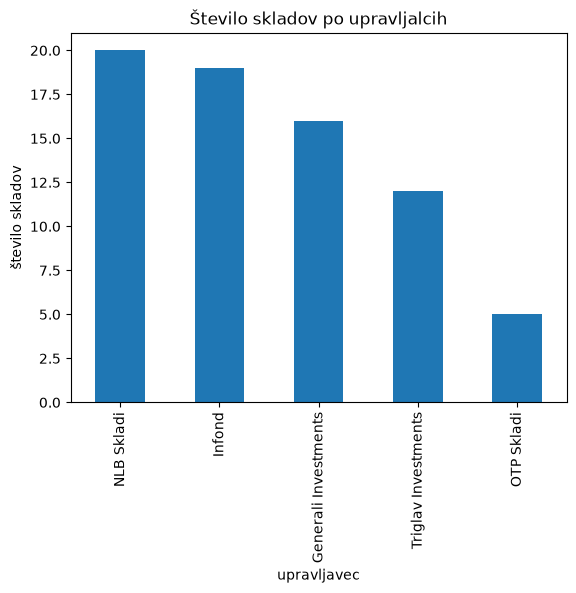

In [315]:
print("Število skladov:", len(skladi))
skladi["upravljavec"].value_counts().plot.bar(
    title="Število skladov po upravljalcih"
)
plt.ylabel("število skladov")
plt.show()


Največ skladov imata NLB Skladi (20) in Infond (19), sledita Generali Investments (16) in Triglav Investments (12), OTP Skladi pa jih imajo le 5.

## Opisna statistika donosov

In [316]:
skladi[["donos_6m", "donos_12m", "donos_60m"]].describe().round(2)


,donos_6m,donos_12m,donos_60m
count,72.00,71.00,71.00
mean,6.94,14.14,42.65
std,5.91,11.38,39.71
min,-5.73,-16.13,-28.91
25%,2.34,7.02,17.88
50%,6.88,14.58,36.40
75%,11.11,19.19,60.15
max,23.22,43.02,169.74


Tabela prikazuje osnovne statistike donosov za 6, 12 in 60 mesecev (vrednosti so v odstotkih).

V zadnjem letu je povprečen sklad prinesel **14,14 %** donosa, mediana pa je 14,58 %. Polovica skladov je torej zaslužila več kot 14,6 %. Razlike med skladi so velike: najslabši je izgubil 16,1 %, najboljši pa pridobil 43,0 %. V zadnjih petih letih je povprečen donos 42,7 %, razpon pa sega od −28,9 % do 169,7 %.

Pri 12- in 60-mesečnem donosu je 71 vrednosti namesto 72, ker sklad Generali Slovenija obstaja šele od februarja 2026 in zanj teh donosov še ni.


## Najdonosnejši skladi v zadnjih petih letih

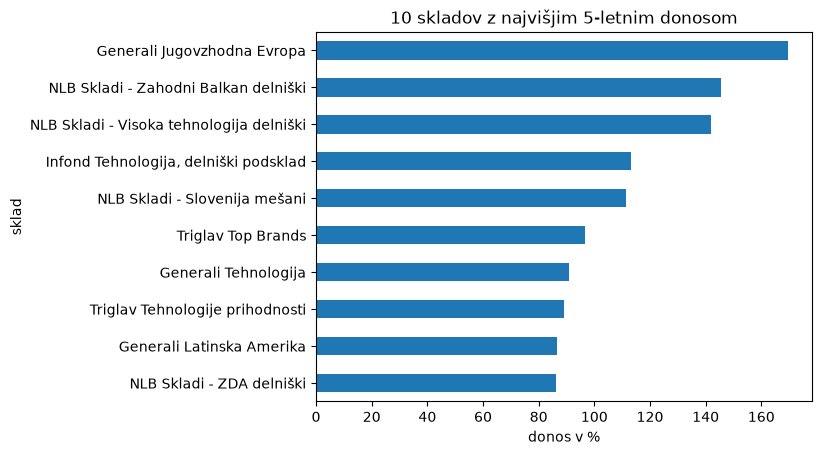

In [317]:
najboljsi = skladi.nlargest(10, "donos_60m").set_index("sklad")
najboljsi["donos_60m"].sort_values().plot.barh(
    title="10 skladov z najvišjim 5-letnim donosom"
)
plt.xlabel("donos v %")
plt.show()


Med desetimi najdonosnejšimi skladi v zadnjih petih letih izstopata dve skupini:

- **Tehnološki skladi** so na lestvici kar štirje: NLB Skladi – Visoka tehnologija (141,9 %), Infond Tehnologija (113,3 %), Generali Tehnologija (90,9 %) in Triglav Tehnologije prihodnosti (89,2 %).
- **Skladi, ki vlagajo v Slovenijo in Jugovzhodno Evropo**, so na samem vrhu: Generali Jugovzhodna Evropa (169,7 %), NLB Skladi – Zahodni Balkan (145,5 %) in NLB Skladi – Slovenija mešani (111,5 %).

Na lestvici so še skladi, vezani na ameriški trg in velike svetovne blagovne znamke (NLB Skladi – ZDA, Triglav Top Brands), ter Generali Latinska Amerika. Vsi najdonosnejši skladi so delniški ali mešani, obvezniških med njimi ni.

### Zakaj gledati daljše obdobje

Vzajemni skladi so namenjeni dolgoročnemu varčevanju, zato je donos v enem letu lahko zavajajoč:

- **En dober ali slab dogodek močno vpliva na kratko obdobje.** Infond Surovine in energija je bil v zadnjem letu drugi najboljši sklad (41,5 %), med desetimi najboljšimi v petih letih pa ga ni. Visok enoletni donos je bil torej posledica dobrega zadnjega leta in ne dolgoročne uspešnosti.
- **V daljšem obdobju se nihanja izravnajo.** Petletni donos pokaže, ali je sklad rasel vztrajno, in ne le, ali je imel srečo v enem letu.

Tudi petletni donos ne zagotavlja, da bo sklad tako uspešen tudi v prihodnje. Pove pa več o tem, kako se je sklad obnesel skozi različne razmere na trgu.

## Najmanj donosni skladi v zadnjih petih letih

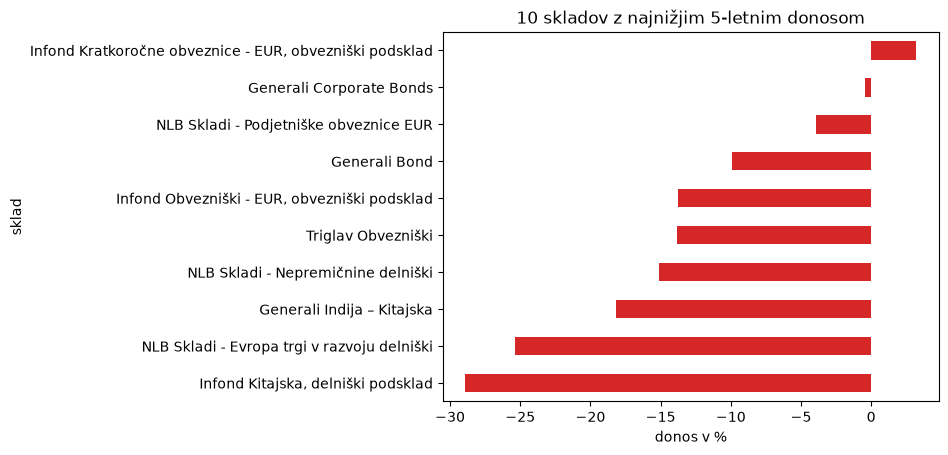

In [318]:
najslabsi = skladi.nsmallest(10, "donos_60m").set_index("sklad")
najslabsi["donos_60m"].sort_values().plot.barh(
    title="10 skladov z najnižjim 5-letnim donosom", color="tab:red"
)
plt.xlabel("donos v %")
plt.show()


V zadnjih petih letih je izgubljalo 9 od 71 skladov. Med desetimi najslabšimi izstopata dve skupini:

- **Skladi, ki vlagajo v Kitajsko in trge v razvoju**, so izgubili največ: Infond Kitajska (−28,9 %), NLB Skladi – Evropa trgi v razvoju (−25,4 %) in Generali Indija – Kitajska (−18,2 %). To so delniški skladi, ki se osredotočajo na eno regijo, zato so zelo odvisni od razmer na tem trgu.
- **Obvezniški skladi** so kar štirje: Triglav Obvezniški (−13,9 %), Infond Obvezniški – EUR (−13,8 %), Generali Bond (−9,9 %) in NLB Skladi – Podjetniške obveznice EUR (−3,9 %). Tudi Generali Corporate Bonds je skoraj na ničli (−0,4 %), Infond Kratkoročne obveznice pa so v petih letih prinesle le 3,2 %.

Obvezniški skladi veljajo za varnejše od delniških, ker njihova vrednost manj niha. V tem obdobju pa so izgubljali tudi oni, kar kaže, da manjše tveganje ne pomeni, da sklad ne more izgubiti. Obvezniški skladi niso premagali niti inflacije: cene so se v Sloveniji v zadnjih petih letih zvišale za 27,0 % (Eurostat, HICP), najboljši obvezniški sklad pa je v tem času prinesel le 11,6 %. Vlagatelji v obvezniške sklade so torej izgubili kupno moč.

Na lestvici je še NLB Skladi – Nepremičnine (−15,2 %).

Dober primer, zakaj je treba gledati daljše obdobje, je NLB Skladi – Evropa trgi v razvoju. V zadnjem letu je prinesel 32,9 % in je bil med najboljšimi skladi, v petih letih pa je še vedno v izgubi 25,4 %. Dobro zadnje leto torej ni pokrilo izgub iz prejšnjih let.

## Primerjava upravljalcev

Za vsakega upravljalca izračunam povprečni donos vseh njegovih skladov v zadnjem letu in v zadnjih petih letih.

In [319]:
po_upravljalcih = (
    skladi.groupby("upravljavec")[["donos_12m", "donos_60m"]]
    .mean()
    .sort_values("donos_60m")
)
po_upravljalcih.round(2)


,donos_12m,donos_60m
upravljavec,,
Infond,11.53,32.14
Triglav Investments,13.78,38.24
OTP Skladi,15.07,38.66
Generali Investments,13.48,49.41
NLB Skladi,17.08,51.21


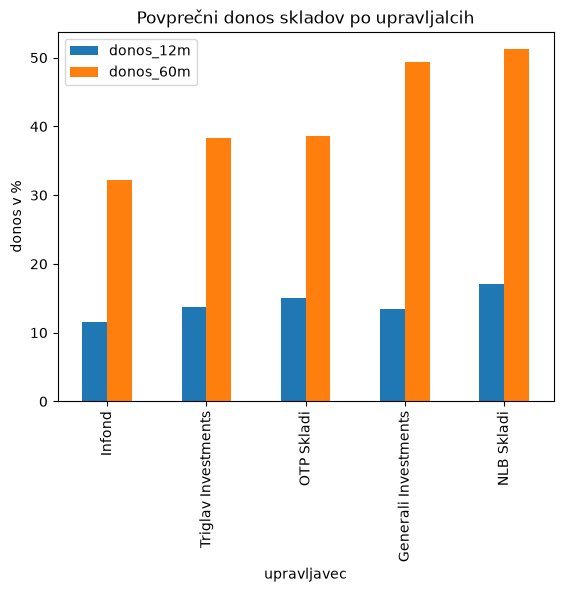

In [320]:
po_upravljalcih.plot.bar(title="Povprečni donos skladov po upravljalcih")
plt.ylabel("donos v %")
plt.show()


V zadnjih petih letih so imeli najvišji povprečni donos skladi NLB Skladov (51,2 %) in Generali Investments (49,4 %). Sledijo OTP Skladi (38,7 %) in Triglav Investments (38,2 %), najnižjega pa ima Infond (32,1 %).

Primerjava ima omejitve: povprečje združuje zelo različne sklade (delniške, obvezniške, denarnega trga), zato je odvisno predvsem od tega, kakšne sklade upravljalec ponuja. OTP Skladi imajo le 5 skladov, zato je njihovo povprečje manj zanesljivo.

## Primerjava skladov različnih upravljalcev na istem področju

Odločil sem se primerjati sklade različnih upravljalcev na istem področju, da se bo videlo kateri od uravljalcev je "najboljši".

### Tehnološki skladi

Tehnološki sklad ponujajo štirje upravljalci: Generali, Infond, NLB Skladi in Triglav. Vsi vlagajo v delnice tehnoloških podjetij, zato me zanima, ali je pomembno, pri katerem upravljalcu vlagaš.

Ker imajo skladi zelo različne VEP, sem vrednosti preračunal v **indeks**: VEP vsakega sklada na prvi dan je 100. Indeks 200 tako pomeni, da se je vrednost podvojila. Graf se začne 14. 12. 2023, ker se podatki za sklad Triglav Tehnologije prihodnosti začnejo šele takrat.


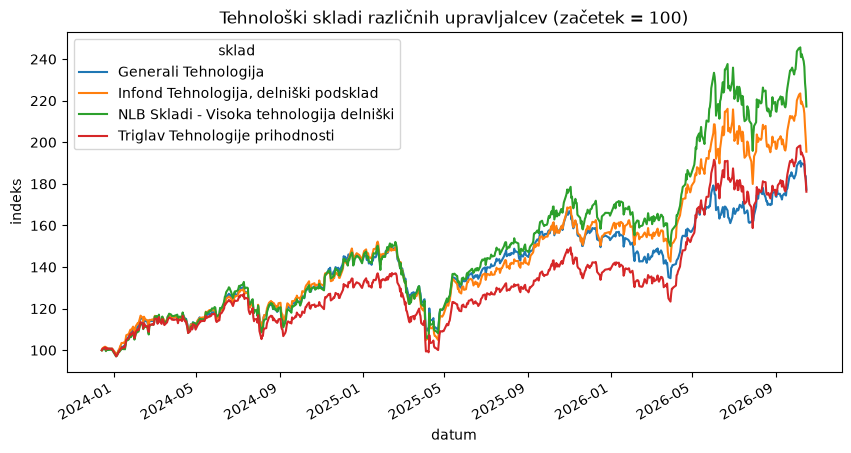

sklad
NLB Skladi - Visoka tehnologija delniški    217.0
Infond Tehnologija, delniški podsklad       195.0
Generali Tehnologija                        177.0
Triglav Tehnologije prihodnosti             176.0
Name: 2026-10-16 00:00:00, dtype: float64

In [321]:
# Ker bom primerjave delal večkrat sem naredil funkcijo

def narisi_primerjavo(izbrani_skladi, naslov):
    """Nariše indeks VEP (prvi skupni dan = 100) za izbrane sklade in
    vrne vrednosti indeksa na zadnji dan."""
    tabela = vep[vep["sklad"].isin(izbrani_skladi)].pivot(
        index="datum", columns="sklad", values="vep"
    )
    tabela = tabela.dropna()
    indeks = tabela / tabela.iloc[0] * 100
    indeks.plot(title=naslov, figsize=(10, 5))
    plt.ylabel("indeks")
    plt.show()
    return indeks.iloc[-1].round().sort_values(ascending=False)

tehnoloski = [
    "Generali Tehnologija",
    "Infond Tehnologija, delniški podsklad",
    "NLB Skladi - Visoka tehnologija delniški",
    "Triglav Tehnologije prihodnosti",
]
narisi_primerjavo(
    tehnoloski, "Tehnološki skladi različnih upravljalcev (začetek = 100)"
)


Vsi štirje skladi se gibljejo zelo podobno: rastejo in padajo ob istem času, na primer ob velikem padcu v začetku aprila 2025. To je pričakovano, saj vlagajo v podobna podjetja.

Razlike so se nabirale postopoma. Od decembra 2023 je največ zrasel NLB Skladi – Visoka tehnologija (indeks 217), sledi Infond Tehnologija (195), Generali Tehnologija (177) in Triglav Tehnologije prihodnosti (176). Pri enakem vložku 1.000 € bi bila razlika med najboljšim in najslabšim skladom približno 410 €.


### Ameriški skladi

Za test sem primerjal še ameriške sklade različnih proizvajalcev.

Ameriški sklad ponujajo štirje upravljalci: NLB Skladi, Infond, Generali in Triglav.

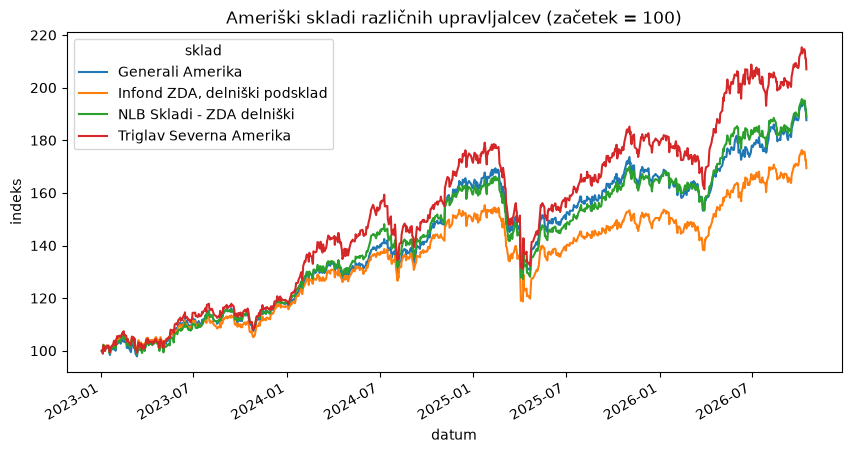

sklad
Triglav Severna Amerika          207.0
NLB Skladi - ZDA delniški        189.0
Generali Amerika                 188.0
Infond ZDA, delniški podsklad    169.0
Name: 2026-10-16 00:00:00, dtype: float64

In [322]:
ameriski = [
    "Generali Amerika",
    "Infond ZDA, delniški podsklad",
    "NLB Skladi - ZDA delniški",
    "Triglav Severna Amerika",
]
narisi_primerjavo(
    ameriski, "Ameriški skladi različnih upravljalcev (začetek = 100)"
)


Pri ameriških skladih je slika podobna: vsi štirje se gibljejo skoraj enako in so v začetku aprila 2025 hkrati padli. Od začetka leta 2023 je največ zrasel Triglav Severna Amerika (indeks 207), sledita NLB Skladi – ZDA (189) in Generali Amerika (188), najmanj pa Infond ZDA (169).

Primerjava obeh področij pokaže, da **noben upravljalec ni najboljši na vseh področjih**: Triglav ima najslabši tehnološki sklad in najboljši ameriški, Infond pa ravno obratno drugega najboljšega tehnološkega in najslabši ameriški. Zato je smiselno primerjati posamezne sklade in ne izbirati le po upravljalcu, če želimo maksimizirati donos.


## Tveganje: volatilnost skladov

**Volatilnost** je v financah mera za to, kako močno se cena naložbe spreminja. Visoka volatilnost pomeni, da vrednost sklada pogosto in močno niha navzgor in navzdol. Skladi imajo načeloma nizko volatilnost, a vseeno prihaja do kar velikih razlik med sektorji.

Volatilnost izračunam tako, da za vsak sklad določim, za koliko odstotkov se je VEP spremenil iz dneva v dan, nato pa izračunam **standardni odklon** teh sprememb. To je **dnevna volatilnost**: pove, za koliko odstotkov se vrednost sklada običajno spremeni v enem dnevu. Tabela prikazuje deset skladov z največjo in najmanjšo volatilnostjo.


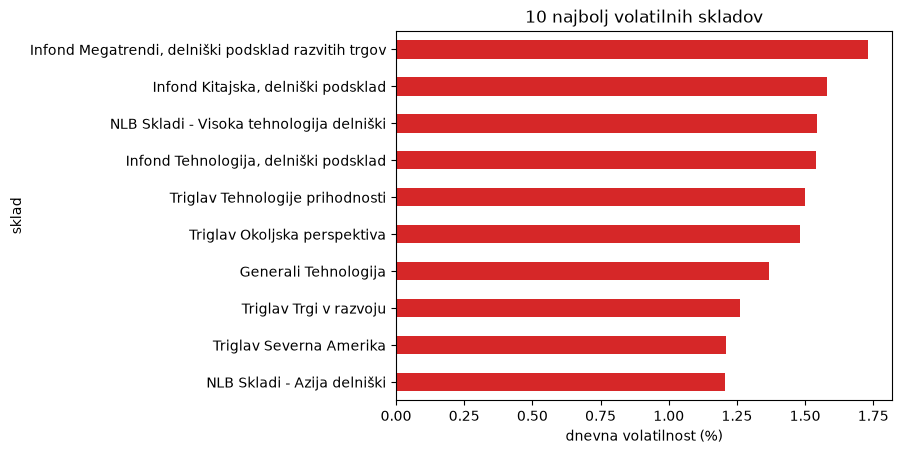

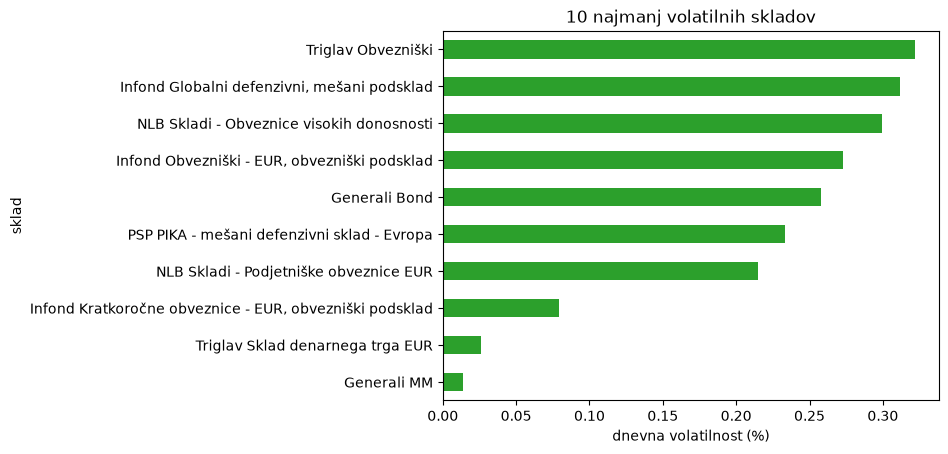

In [323]:
vep = vep.sort_values(["sklad", "datum"])
vep["sprememba"] = vep.groupby("sklad")["vep"].pct_change() * 100
volatilnost = vep.groupby("sklad")["sprememba"].std().rename("volatilnost")

volatilnost.nlargest(10).sort_values().plot.barh(
    title="10 najbolj volatilnih skladov", color="tab:red"
)
plt.xlabel("dnevna volatilnost (%)")
plt.show()

volatilnost.nsmallest(10).sort_values().plot.barh(
    title="10 najmanj volatilnih skladov", color="tab:green"
)
plt.xlabel("dnevna volatilnost (%)")
plt.show()


**Najbolj volatilni** so skoraj sami delniški skladi, ki vlagajo v eno panogo ali regijo: kar štirje tehnološki skladi (NLB Skladi – Visoka tehnologija, Infond Tehnologija, Triglav Tehnologije prihodnosti in Generali Tehnologija), sklad Megatrendi ter skladi, usmerjeni v Kitajsko, Azijo in trge v razvoju. Njihova vrednost se v povprečju spremeni za 1,2 do 1,7 % na dan.

**Najmanj volatilni** so skladi denarnega trga, obvezniški skladi in mešani defenzivni skladi. Generali MM in Triglav Sklad denarnega trga EUR se na dan spremenita le za 0,01 oziroma 0,03 %, ostali pa za okoli 0,2 do 0,3 %. To je približno petkrat manj kot pri najbolj volatilnih skladih. Pri primerjavi grafov je treba paziti na različno merilo na vodoravni osi.

Zanima me še, ali bolj tvegani skladi prinašajo tudi višji donos. Na spodnjem grafu je vsaka točka en sklad.


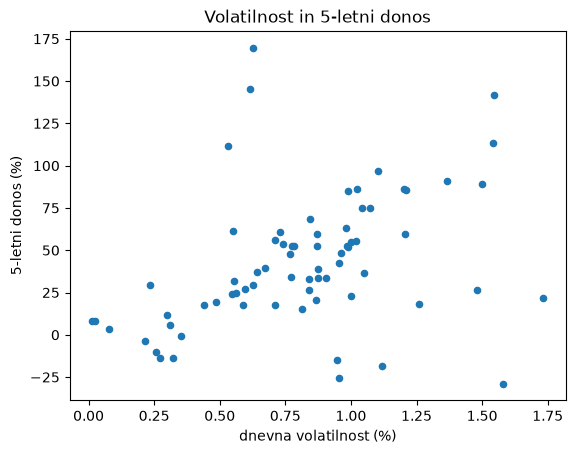

Korelacija: 0.36


In [324]:
skladi = skladi.join(volatilnost, on="sklad")
skladi.plot.scatter(
    x="volatilnost", y="donos_60m", title="Volatilnost in 5-letni donos"
)
plt.xlabel("dnevna volatilnost (%)")
plt.ylabel("5-letni donos (%)")
plt.show()
korelacija = skladi["volatilnost"].corr(skladi["donos_60m"])
print("Korelacija:", round(korelacija, 2))



Korelacija med volatilnostjo in petletnim donosom je 0,36, kar pomeni zmerno pozitivno povezanost: bolj tvegani skladi so v povprečju prinesli več.

Razlika je velika. 11 najmanj volatilnih skladov (pod 0,4 %) je v petih letih prineslo povprečno le 2,2 %, 11 najbolj volatilnih (nad 1,2 %) pa povprečno 64 %. Višje tveganje pa ne zagotavlja višjega donosa: med najbolj volatilnimi skladi je tako najboljši, NLB Skladi – Visoka tehnologija (141,9 %), kot tudi najslabši, Infond Kitajska (−28,9 %).

## Sklep

V zadnjih petih letih so bili najdonosnejši delniški skladi, ki vlagajo v tehnologijo ter v Slovenijo in Jugovzhodno Evropo. Najvišji donos je imel Generali Jugovzhodna Evropa (169,7 %). Najslabše so se odrezali skladi, usmerjeni v Kitajsko, in obvezniški skladi. Slednji niso premagali niti inflacije (27,0 %), zato so vlagatelji v njih izgubili kupno moč.

Med upravljalci so imeli najvišji povprečni donos NLB Skladi, najnižjega pa Infond, vendar je ta primerjava omejena, ker povprečje združuje zelo različne sklade. Primerjava skladov z enako usmeritvijo je pokazala, da noben upravljalec ni najboljši na vseh področjih.

Bolj volatilni skladi so v povprečju prinesli višji donos (korelacija 0,36), a tudi večje padce. Na vprašanje, kam se je splačalo vlagati, je torej odgovor: v razpršene delniške sklade za daljše obdobje, ob tem pa je treba sprejeti večja nihanja vrednosti.

Analiza temelji na preteklih donosih, ki ne zagotavljajo prihodnjih. Ne upošteva niti stroškov skladov (vstopnih stroškov in provizije za upravljanje), ki donos vlagatelja še zmanjšajo.
